In [2]:
# =========================================
# 01_data_cleaning.ipynb
# =========================================

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [6]:
RAW_PATH = Path("C:\\Users\\badra\\Downloads\\individual+household+electric+power+consumption\\household_power_consumption.txt")
PROCESSED_DIR = Path("C:\\Users\\badra\\Downloads\\data")
OUTPUTS_DIR = Path("C:\\Users\\badra\\Downloads\\outputs")

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

In [23]:
df = pd.read_csv(
    RAW_PATH,
    sep=';',
    na_values=['?'],
    low_memory=False
)

In [24]:
print("Shape before cleaning:", df.shape)
print(df.head())
print(df.info())

Shape before cleaning: (2075259, 9)
         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  
<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 20

In [9]:
# -----------------------------
# combine date and time
# -----------------------------
df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

In [10]:
# drop original columns
df.drop(columns=["Date", "Time"], inplace=True)

In [11]:
# -----------------------------
# numeric conversion
# -----------------------------
numeric_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [12]:
# -----------------------------
# remove rows with invalid datetime
# -----------------------------
df = df.dropna(subset=["datetime"])

In [13]:
# sort and set index
df = df.sort_values("datetime").set_index("datetime")

In [14]:
print("\nMissing values before interpolation:")
print(df.isna().sum())


Missing values before interpolation:
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


In [15]:

# -----------------------------
# interpolate missing values
# -----------------------------
df = df.interpolate(method="time")
df = df.ffill().bfill()

In [16]:
print("\nMissing values after interpolation:")
print(df.isna().sum())


Missing values after interpolation:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64


In [17]:
# -----------------------------
# create unmetered energy column
# -----------------------------
df["unmetered_energy"] = (
    df["Global_active_power"] * 1000 / 60
    - df["Sub_metering_1"]
    - df["Sub_metering_2"]
    - df["Sub_metering_3"]
)


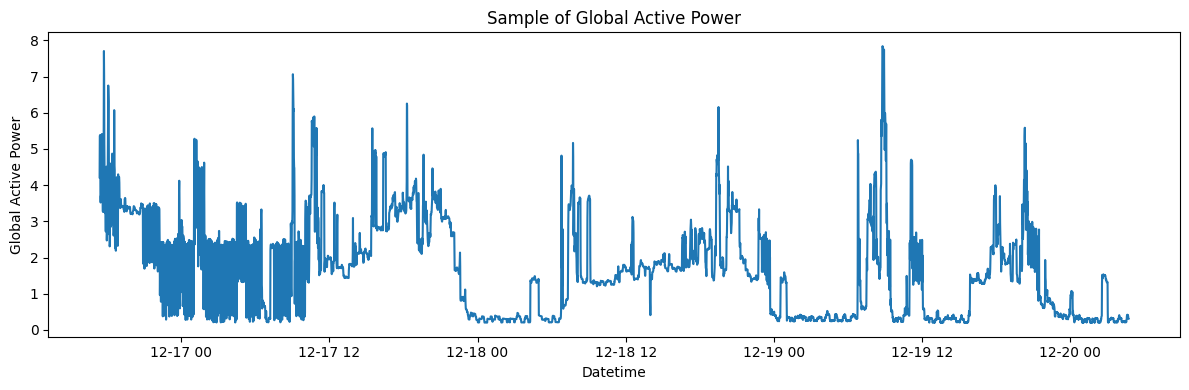

In [18]:
# -----------------------------
# basic plots
# -----------------------------
plt.figure(figsize=(12, 4))
plt.plot(df.index[:5000], df["Global_active_power"].iloc[:5000])
plt.title("Sample of Global Active Power")
plt.xlabel("Datetime")
plt.ylabel("Global Active Power")
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / "sample_global_active_power.png")
plt.show()

In [19]:
# -----------------------------
# save cleaned data
# -----------------------------
df.to_csv(PROCESSED_DIR / "cleaned_energy.csv")

print("\nSaved cleaned_energy.csv")


Saved cleaned_energy.csv


In [20]:
# -----------------------------
# resampling
# -----------------------------
hourly_df = df.resample("h").agg({
    "Global_active_power": "mean",
    "Global_reactive_power": "mean",
    "Voltage": "mean",
    "Global_intensity": "mean",
    "Sub_metering_1": "sum",
    "Sub_metering_2": "sum",
    "Sub_metering_3": "sum",
    "unmetered_energy": "sum"
})

In [21]:
daily_df = df.resample("D").agg({
    "Global_active_power": "mean",
    "Global_reactive_power": "mean",
    "Voltage": "mean",
    "Global_intensity": "mean",
    "Sub_metering_1": "sum",
    "Sub_metering_2": "sum",
    "Sub_metering_3": "sum",
    "unmetered_energy": "sum"
})


In [22]:
hourly_df.to_csv(PROCESSED_DIR / "hourly_energy.csv")
daily_df.to_csv(PROCESSED_DIR / "daily_energy.csv")

print("Saved hourly_energy.csv")
print("Saved daily_energy.csv")

print("\nHourly shape:", hourly_df.shape)
print("Daily shape:", daily_df.shape)
print(daily_df.head())

Saved hourly_energy.csv
Saved daily_energy.csv

Hourly shape: (34589, 8)
Daily shape: (1442, 8)
            Global_active_power  Global_reactive_power     Voltage  \
datetime                                                             
2006-12-16             3.053475               0.088187  236.243763   
2006-12-17             2.354486               0.156949  240.087028   
2006-12-18             1.530435               0.112356  241.231694   
2006-12-19             1.157079               0.104821  241.999313   
2006-12-20             1.545658               0.111804  242.308062   

            Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  \
datetime                                                                       
2006-12-16         13.082828             0.0           546.0          4926.0   
2006-12-17          9.999028          2033.0          4187.0         13341.0   
2006-12-18          6.421667          1063.0          2621.0         14018.0   
2006-12-19   